# Bibliotecas

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
import itertools
import statsmodels.api as sm

# Importação e análise dos datasets

In [ ]:
df_errors = pd.read_csv('/content/drive/MyDrive/Microsoft Azure Predictive Maintenance/PdM_errors.csv', sep=',', encoding='utf-8')
df_failures = pd.read_csv('/content/drive/MyDrive/Microsoft Azure Predictive Maintenance/PdM_failures.csv', sep=',', encoding='utf-8')
df_machines = pd.read_csv('/content/drive/MyDrive/Microsoft Azure Predictive Maintenance/PdM_machines.csv', sep=',', encoding='utf-8')
df_maint = pd.read_csv('/content/drive/MyDrive/Microsoft Azure Predictive Maintenance/PdM_maint.csv', sep=',', encoding='utf-8')
df_telemetry = pd.read_csv('/content/drive/MyDrive/Microsoft Azure Predictive Maintenance/PdM_telemetry.csv', sep=',', encoding='utf-8')

**Source**
https://www.kaggle.com/datasets/arnabbiswas1/microsoft-azure-predictive-maintenance

**Details**

* Telemetry Time Series Data (PdM_telemetry.csv): It consists of hourly average of voltage, rotation, pressure, vibration collected from 100 machines for the year 2015.

* Error (PdM_errors.csv): These are errors encountered by the machines while in operating condition. Since, these errors don't shut down the machines, these are not considered as failures. The error date and times are rounded to the closest hour since the telemetry data is collected at an hourly rate.

* Maintenance (PdM_maint.csv): If a component of a machine is replaced, that is captured as a record in this table. Components are replaced under two situations: 1. During the regular scheduled visit, the technician replaced it (Proactive Maintenance) 2. A component breaks down and then the technician does an unscheduled maintenance to replace the component (Reactive Maintenance). This is considered as a failure and corresponding data is captured under Failures. Maintenance data has both 2014 and 2015 records. This data is rounded to the closest hour since the telemetry data is collected at an hourly rate.

* Failures (PdM_failures.csv): Each record represents replacement of a component due to failure. This data is a subset of Maintenance data. This data is rounded to the closest hour since the telemetry data is collected at an hourly rate.

* Metadata of Machines (PdM_Machines.csv): Model type & age of the Machines.

In [ ]:
df_errors.head()

,datetime,machineID,errorID
0,2015-01-03 07:00:00,1,error1
1,2015-01-03 20:00:00,1,error3
2,2015-01-04 06:00:00,1,error5
3,2015-01-10 15:00:00,1,error4
4,2015-01-22 10:00:00,1,error4


In [ ]:
df_failures.head()

,datetime,machineID,failure
0,2015-01-05 06:00:00,1,comp4
1,2015-03-06 06:00:00,1,comp1
2,2015-04-20 06:00:00,1,comp2
3,2015-06-19 06:00:00,1,comp4
4,2015-09-02 06:00:00,1,comp4


In [ ]:
df_machines.head()

,machineID,model,age
0,1,model3,18
1,2,model4,7
2,3,model3,8
3,4,model3,7
4,5,model3,2


In [ ]:
df_maint.head()

,datetime,machineID,comp
0,2014-06-01 06:00:00,1,comp2
1,2014-07-16 06:00:00,1,comp4
2,2014-07-31 06:00:00,1,comp3
3,2014-12-13 06:00:00,1,comp1
4,2015-01-05 06:00:00,1,comp4


In [ ]:
df_telemetry.head()

,datetime,machineID,volt,rotate,pressure,vibration
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686
1,2015-01-01 07:00:00,1,162.879223,402.747490,95.460525,43.413973
2,2015-01-01 08:00:00,1,170.989902,527.349825,75.237905,34.178847
3,2015-01-01 09:00:00,1,162.462833,346.149335,109.248561,41.122144
4,2015-01-01 10:00:00,1,157.610021,435.376873,111.886648,25.990511


**Analise da máquina**

In [ ]:
id_maquina = 13

In [ ]:
df_maquina = df_telemetry.loc[df_telemetry['machineID'] == id_maquina].reset_index(drop=True)
df_maquina.head()

,datetime,machineID,volt,rotate,pressure,vibration
0,2015-01-01 06:00:00,13,155.172892,456.320444,96.090782,32.522588
1,2015-01-01 07:00:00,13,183.752447,439.656853,102.744687,37.099813
2,2015-01-01 08:00:00,13,174.731896,399.487309,114.171005,34.519719
3,2015-01-01 09:00:00,13,159.881546,461.922370,95.503275,43.790212
4,2015-01-01 10:00:00,13,174.588451,459.084780,94.029010,41.195627


In [ ]:
df_falhas = df_failures.loc[df_failures['machineID'] == id_maquina].reset_index(drop=True)
df_falhas.head()

,datetime,machineID,failure
0,2015-04-11 06:00:00,13,comp3
1,2015-04-11 06:00:00,13,comp4
2,2015-06-10 06:00:00,13,comp3
3,2015-06-25 06:00:00,13,comp4
4,2015-07-10 06:00:00,13,comp2


In [ ]:
df_erros = df_errors.loc[df_errors['machineID'] == id_maquina].reset_index(drop=True)
df_erros.head()

,datetime,machineID,errorID
0,2015-01-10 04:00:00,13,error5
1,2015-01-13 21:00:00,13,error3
2,2015-01-26 09:00:00,13,error2
3,2015-01-27 07:00:00,13,error1
4,2015-01-28 20:00:00,13,error1


**Análise gráfica**

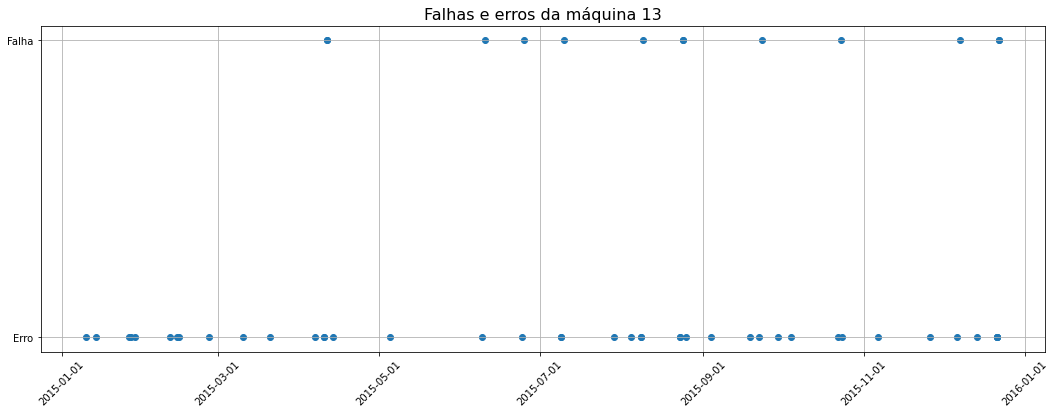

In [ ]:
fig, ax = plt.subplots()

# For a simpler plot, we will use two different values in the y-axis to differentiate between error and failure
y_category = list()

for iter in range(0, len(df_falhas)):
  y_category.append('Falha')

for iter in range(0, len(df_erros)):
  y_category.append('Erro')

# Get timestamp from error and selected failure
df_timestamp = pd.concat([df_falhas['datetime'], df_erros['datetime']], ignore_index=True, axis=0)
df_plot = pd.DataFrame({'timestamp': df_timestamp, 'category': y_category})
df_plot.loc[:, 'timestamp'] = pd.to_datetime(df_plot.loc[:, 'timestamp'])
df_plot.sort_values(by=['timestamp'], inplace=True, ignore_index=True)


# Plot the data with timestamp as x-axis
ax.scatter('timestamp', 'category', data = df_plot)
yearfmt = mdates.DateFormatter('%Y-%m-%d')
ax.set_title('Falhas e erros da máquina 13', fontsize=16)
ax.xaxis.set_major_formatter(yearfmt)
ax.tick_params(axis='x', rotation=45)
ax.figure.set_size_inches(18, 6)
ax.grid()

As falhas ocorreram após alguns erros e alguns erros resultaram em falhas imediatas.

In [ ]:
df_plot.groupby('category').count()

,timestamp
category,
Erro,42
Falha,13


In [ ]:
# Visualização das datas onde houveram falhas na máquina 13
datas_falhas = df_plot.loc[df_plot['category'] == 'Falha']
print(datas_falhas)

             timestamp category
14 2015-04-11 06:00:00    Falha
15 2015-04-11 06:00:00    Falha
19 2015-06-10 06:00:00    Falha
21 2015-06-25 06:00:00    Falha
24 2015-07-10 06:00:00    Falha
29 2015-08-09 06:00:00    Falha
32 2015-08-24 06:00:00    Falha
33 2015-08-24 06:00:00    Falha
38 2015-09-23 06:00:00    Falha
42 2015-10-23 06:00:00    Falha
47 2015-12-07 06:00:00    Falha
53 2015-12-22 06:00:00    Falha
54 2015-12-22 06:00:00    Falha


In [ ]:
# Visualização das datas onde houveram erros na máquina 13
datas_erros = df_plot.loc[df_plot['category'] == 'Erro']
print(datas_erros)

             timestamp category
0  2015-01-10 04:00:00     Erro
1  2015-01-13 21:00:00     Erro
2  2015-01-26 09:00:00     Erro
3  2015-01-27 07:00:00     Erro
4  2015-01-28 20:00:00     Erro
5  2015-02-10 20:00:00     Erro
6  2015-02-13 10:00:00     Erro
7  2015-02-14 05:00:00     Erro
8  2015-02-25 20:00:00     Erro
9  2015-03-10 18:00:00     Erro
10 2015-03-20 16:00:00     Erro
11 2015-04-06 23:00:00     Erro
12 2015-04-10 06:00:00     Erro
13 2015-04-10 06:00:00     Erro
16 2015-04-13 18:00:00     Erro
17 2015-05-05 09:00:00     Erro
18 2015-06-09 06:00:00     Erro
20 2015-06-24 06:00:00     Erro
22 2015-07-09 06:00:00     Erro
23 2015-07-09 06:00:00     Erro
25 2015-07-29 04:00:00     Erro
26 2015-08-04 18:00:00     Erro
27 2015-08-08 06:00:00     Erro
28 2015-08-08 06:00:00     Erro
30 2015-08-23 06:00:00     Erro
31 2015-08-23 06:00:00     Erro
34 2015-08-25 15:00:00     Erro
35 2015-09-03 20:00:00     Erro
36 2015-09-18 22:00:00     Erro
37 2015-09-22 06:00:00     Erro
39 2015-

In [ ]:
# Conversão de timestamp para datetime
df_maquina.loc[:, 'datetime'] = pd.to_datetime(df_maquina.loc[:, 'datetime'])

# Obtenção do index da data
data = '2015-04-10'
index_data_falha = df_maquina.loc[df_maquina['datetime'] == data].index.values[0]

# Dados da telemetria na máquina 13 7 semanas antes e 7 semanas depois da data de erro 
dados_telemetria = df_maquina.loc[index_data_falha - 7*24 : index_data_falha + 7*24, :]

**Análise gráfica das grandezas**

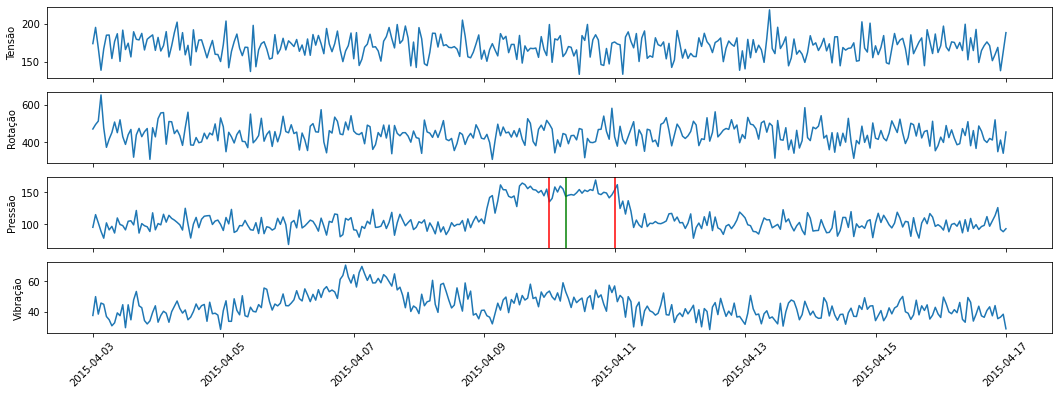

In [ ]:
import datetime as dt

fig, ax = plt.subplots(nrows=4, sharex=True)
fig.set_size_inches(18, 6)

ax[0].plot('datetime', 'volt', data=dados_telemetria)
ax[0].set_ylabel('Tensão')

ax[1].plot('datetime', 'rotate', data=dados_telemetria)
ax[1].set_ylabel('Rotação')

ax[2].plot('datetime', 'pressure', data=dados_telemetria)
ax[2].set_ylabel('Pressão')
ax[2].axvline(dt.datetime.strptime('2015-04-10 00:00:00', '%Y-%m-%d %H:%M:%S'), color='red') # Começo análise
ax[2].axvline(dt.datetime.strptime('2015-04-10 06:00:00', '%Y-%m-%d %H:%M:%S'), color='green') # Erro
ax[2].axvline(dt.datetime.strptime('2015-04-11 00:00:00', '%Y-%m-%d %H:%M:%S'), color='red') # Fim análise

ax[3].plot('datetime', 'vibration', data=dados_telemetria)
ax[3].set_ylabel('Vibração')
ax[3].tick_params(axis='x', rotation=45)

A pressão foi a grandeza que sofreu anormalidade mais notável na data do erro e falha. Ela será a variável preditora do modelo.

# Análise de estacionariedade

**Não é estacionário se houver:**

* Tendência de crescimento ou decrescimento em toda a série temporal

Ou

* Sazonalidade (repetições com frequência fixa)

**É estacionária quando:**

* A média e a variância são constantes ao longo do tempo (sem tendência e/ou sem **sazonalidade**

Text(0.5, 0, '')

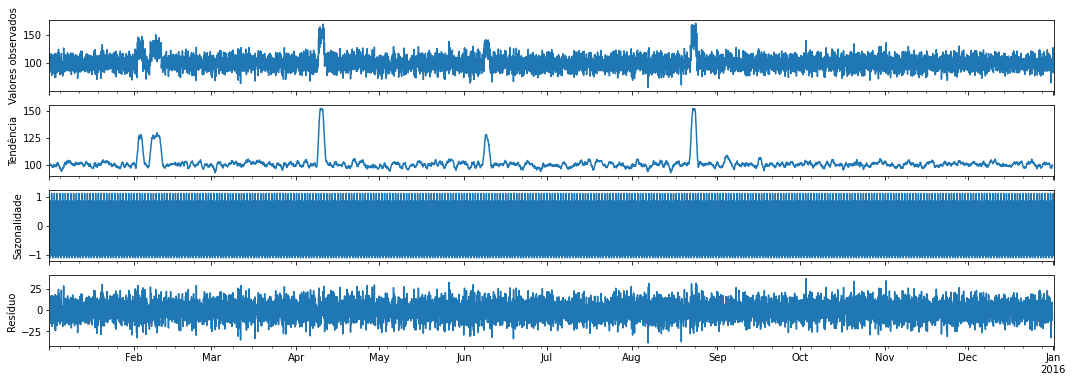

In [ ]:
df_maquina.set_index('datetime', inplace=True)

resultados = seasonal_decompose(df_maquina['pressure'], period=24) # period = 24 (horas)

fig, (ax1,ax2,ax3, ax4) = plt.subplots(4, figsize=(18, 6), sharex=True)
fig.set_size_inches(18, 6)

ax1 = resultados.observed.plot(ax=ax1) # Valores observados
ax1.set_ylabel('Valores observados')

ax2 = resultados.trend.plot(ax=ax2) # Tendência
ax2.set_ylabel('Tendência')

ax3 = resultados.seasonal.plot(ax=ax3) # Sazonalidade
ax3.set_ylabel('Sazonalidade')

ax4 = resultados.resid.plot(ax=ax4) # Resíduo
ax4.set_ylabel('Resíduo')
ax4.set_xlabel(None)

A série (pressão) apresenta sazonalidade, portanto não é estacionária.

## Teste ADF

Hipótese nula: a série é não estacionária e é dependente do tempo.

Hipótese alternativa: a série é estacionária.

Caso o p_valor esteja abaixo de um valor limite (nível de significância), a hipótese nula é rejeitada e a série é considerada estacionária.

In [ ]:
p_valor = adfuller(df_maquina['pressure'].dropna())[1]

p_valor

1.4664757277623184e-18

## ??? Problema a ser resolvido ???

Se o p_valor for menor que o nível de significância (aqui definido 0,05), a série é estacionária.

Porém, na análise gráfica foi verificado que há sazonalidade.

**Primeira diferenciação**

Text(0.5, 0, '')

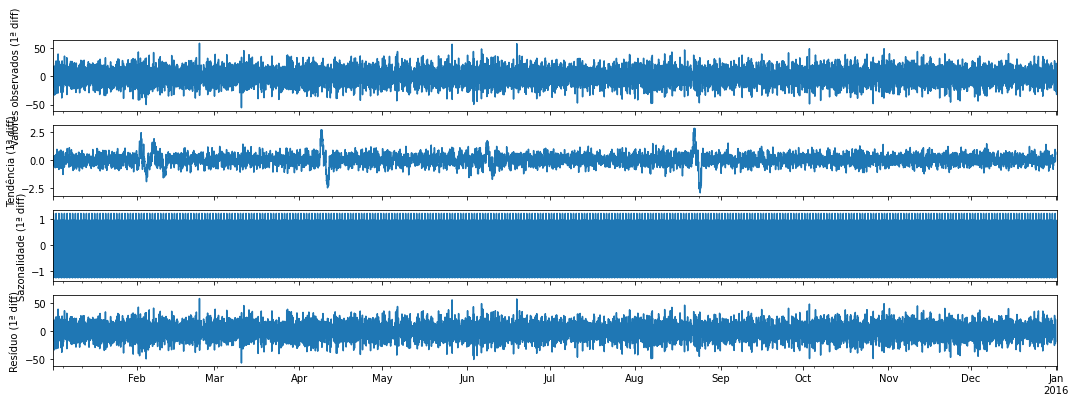

In [ ]:
resultados_diff = seasonal_decompose(df_maquina['pressure'].diff().dropna(), period=24)

fig, (ax1,ax2,ax3, ax4) = plt.subplots(4, figsize=(18, 6), sharex=True)
fig.set_size_inches(18, 6)

ax1 = resultados_diff.observed.plot(ax=ax1)
ax1.set_ylabel('Valores observados (1ª diff)')

ax2 = resultados_diff.trend.plot(ax=ax2)
ax2.set_ylabel('Tendência (1ª diff)')

ax3 = resultados_diff.seasonal.plot(ax=ax3)
ax3.set_ylabel('Sazonalidade (1ª diff)')

ax4 = resultados_diff.resid.plot(ax=ax4)
ax4.set_ylabel('Resíduo (1ª diff)')
ax4.set_xlabel(None)

**Segunda diferenciação**

Text(0.5, 0, '')

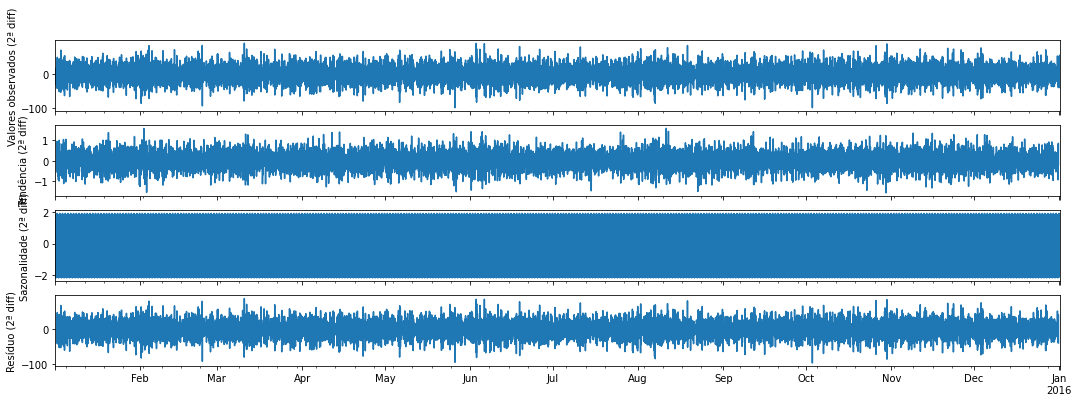

In [ ]:
resultados_diff = seasonal_decompose(df_maquina['pressure'].diff().diff().dropna(), period=24)

fig, (ax1,ax2,ax3, ax4) = plt.subplots(4, figsize=(18, 6), sharex=True)
fig.set_size_inches(18, 6)

ax1 = resultados_diff.observed.plot(ax=ax1)
ax1.set_ylabel('Valores observados (2ª diff)')

ax2 = resultados_diff.trend.plot(ax=ax2)
ax2.set_ylabel('Tendência (2ª diff)')

ax3 = resultados_diff.seasonal.plot(ax=ax3)
ax3.set_ylabel('Sazonalidade (2ª diff)')

ax4 = resultados_diff.resid.plot(ax=ax4)
ax4.set_ylabel('Resíduo (2ª diff)')
ax4.set_xlabel(None)

# Autocorrelação

Mede o quanto duas observações da mesma série temporal estão linearmente relacionadas

(Lags são os valores observados)

In [ ]:
significancia = 0.05

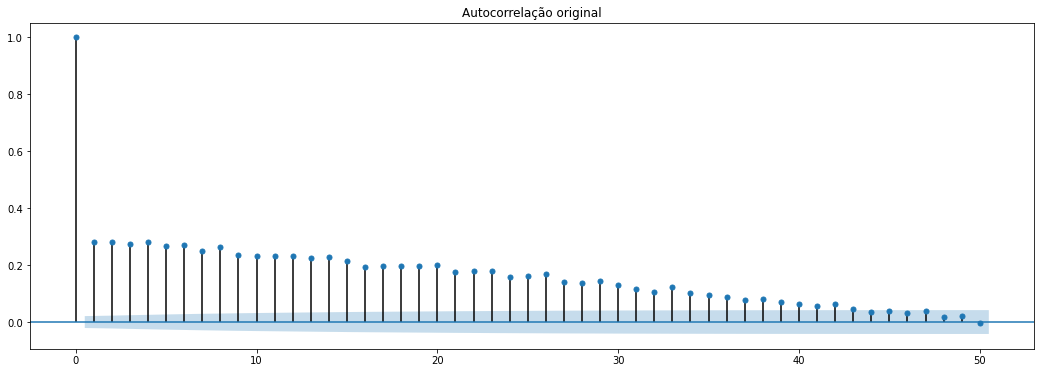

In [ ]:
autocorr = plot_acf(df_maquina['pressure'], lags=50, title='Autocorrelação original', alpha=significancia)
autocorr.set_figheight(6)
autocorr.set_figwidth(18)
plt.show()

A pressão tem correlação positiva e fraca com as outras grandezas

## **Primeira diferenciação**

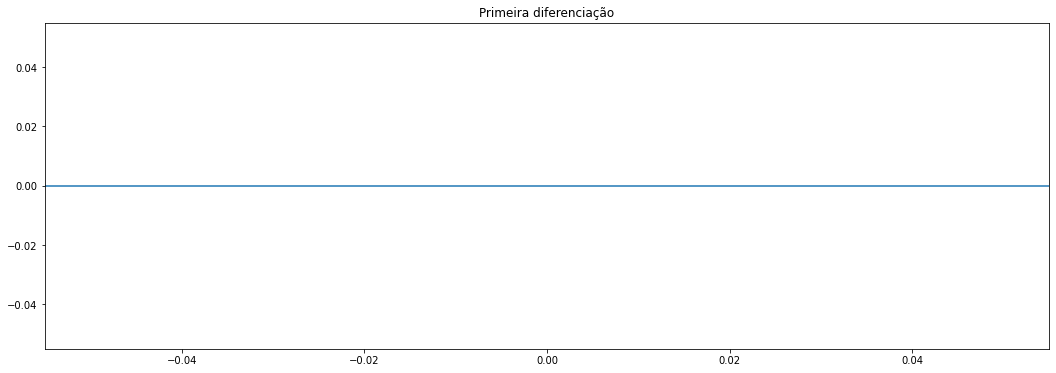

In [ ]:
primeira_diff = df_maquina['pressure'].diff()
autocorr = plot_acf(primeira_diff, title='Primeira diferenciação')
autocorr.set_figheight(6)
autocorr.set_figwidth(18)
plt.show()

# Autocorrelação parcial

Determina a correlação entre o dado observado e o resíduo

São os valores que ficam após os efeitos dos lags anteriores serem removidos

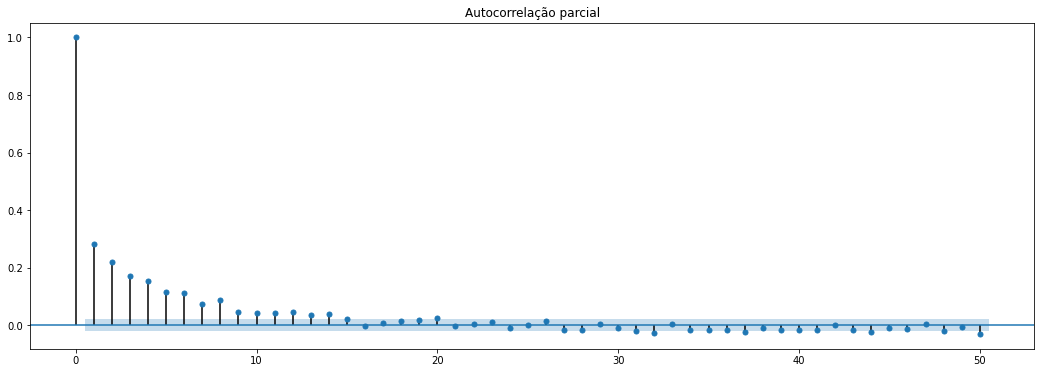

In [ ]:
autocorr_parc = plot_pacf(df_maquina['pressure'], lags=50, title='Autocorrelação parcial', alpha=significancia)
autocorr_parc.set_figheight(6)
autocorr_parc.set_figwidth(18)
plt.show()

A correlação entre valores em dois pontos do timestamp são fracas.
Essa informação é útil para determinar o lag utilizado no modelo.

## **Primeira diferenciação**

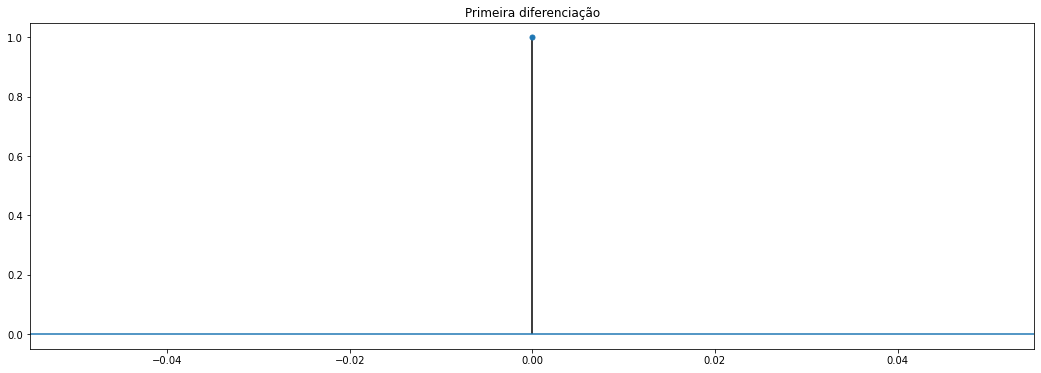

In [ ]:
autocorr_parc = plot_pacf(df_maquina['pressure'].diff(), title='Primeira diferenciação')
autocorr_parc.set_figheight(6)
autocorr_parc.set_figwidth(18)
plt.show()

# ARIMA

p = Número de valores passados para previsão

d = Número de diferenciações (df.diff()) da série para torná-la estacionária

q = Número de valores dos erros das previsões passadas

[Quick way to find p, d and q values for ARIMA](https://analyticsindiamag.com/quick-way-to-find-p-d-and-q-values-for-arima/)

In [ ]:
p, d, q = (1, 0, 1)

modelo_arima = ARIMA(df_maquina['pressure'], order=(p, d, q), freq='H')

modelo_fit = modelo_arima.fit()
modelo_fit.summary()

/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/base/tsa_model.py:524: ValueWarning: No frequency information was provided, so inferred frequency H will be used.
  warnings.warn('No frequency information was'


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:               pressure   No. Observations:                 8761
Model:                 ARIMA(1, 0, 1)   Log Likelihood              -33099.573
Date:                Thu, 05 Jan 2023   AIC                          66207.146
Time:                        17:21:39   BIC                          66235.458
Sample:                    01-01-2015   HQIC                         66216.793
                         - 01-01-2016                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        101.2627      0.644    157.267      0.000     100.001     102.525
ar.L1          0.9758      0.002    421.075      0.000       0.971       0.980
ma.L1         -0.8636      0.006   -155.469      0.000      -0.874      -0.853
sigma2       111.9676      1.619     69.147      0.000     108.794     115.141
===================================================================================
Ljung-Box (L1) (Q):                   2.15   Jarque-Bera (JB):                27.61
Prob(Q):                              0.14   Prob(JB):                         0.00
Heteroskedasticity (H):               0.89   Skew:                             0.03
Prob(H) (two-sided):                  0.00   Kurtosis:                         3.27
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

**AIC**

Utilizada para avaliar a qualidade do ajuste de modelo
Compara o resultado obtido e a distância até o modelo estatístico real

**BIC**

Estimativa da função de probilidade do modelo ser verdadeiro

# SARIMAX

In [ ]:
p = d = q = range(0, 2)

pdq = list(itertools.product(p, d, q))
# Variação dos parâmetros p, d, q e criação de lista com as combinações possíveis

pdq

[(0, 0, 0),
 (0, 0, 1),
 (0, 1, 0),
 (0, 1, 1),
 (1, 0, 0),
 (1, 0, 1),
 (1, 1, 0),
 (1, 1, 1)]

In [ ]:
# Forma dos parâmetros
# Período da sazonalidade - 24 h
seasonal_pdq = [(x[0], x[1], x[2], 24) for x in pdq]

print('Exemplo de combinação de parâmetros para o SARIMAX')
print('SARIMAX: {} x {}'.format(pdq[0], seasonal_pdq[0]))
print('SARIMAX: {} x {}'.format(pdq[0], seasonal_pdq[1]))
print('SARIMAX: {} x {}'.format(pdq[0], seasonal_pdq[2]))

Exemplo de combinação de parâmetros para o SARIMAX
SARIMAX: (0, 0, 0) x (0, 0, 0, 24)
SARIMAX: (0, 0, 0) x (0, 0, 1, 24)
SARIMAX: (0, 0, 0) x (0, 1, 0, 24)


In [ ]:
y = df_maquina['pressure']

aic_lista = []

In [ ]:
# Cálculo do SARIMAX para cada combinação de dados
for param in pdq: # Iteração sobre a parte não sazonal
    for param_seasonal in seasonal_pdq: # Iteração sobre parâmetros sazonais
        mod = sm.tsa.statespace.SARIMAX(y,
                                        order=param,
                                        seasonal_order=param_seasonal)
        resultados = mod.fit()
        aic_lista.append('{}, {}, {}'.format(param, param_seasonal, resultados.aic))

/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/base/tsa_model.py:524: ValueWarning: No frequency information was provided, so inferred frequency H will be used.
  warnings.warn('No frequency information was'
/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/base/tsa_model.py:524: ValueWarning: No frequency information was provided, so inferred frequency H will be used.
  warnings.warn('No frequency information was'
/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/base/tsa_model.py:524: ValueWarning: No frequency information was provided, so inferred frequency H will be used.
  warnings.warn('No frequency information was'
/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/base/tsa_model.py:524: ValueWarning: No frequency information was provided, so inferred frequency H will be used.
  warnings.warn('No frequency information was'
/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/base/tsa_model.py:524: ValueWarning: No frequency information was provided, so in

In [ ]:
aic_lista

['(0, 0, 0), (0, 0, 0, 24), 105895.3171702331',
 '(0, 0, 0), (0, 0, 1, 24), 96048.70209962016',
 '(0, 0, 0), (0, 1, 0, 24), 72617.19927939802',
 '(0, 0, 0), (0, 1, 1, 24), 68207.61011728429',
 '(0, 0, 0), (1, 0, 0, 24), 72858.533568476',
 '(0, 0, 0), (1, 0, 1, 24), 68647.19366832834',
 '(0, 0, 0), (1, 1, 0, 24), 70964.0899255961',
 '(0, 0, 0), (1, 1, 1, 24), 67991.58577643009',
 '(0, 0, 1), (0, 0, 0, 24), 96070.75974287726',
 '(0, 0, 1), (0, 0, 1, 24), 89607.1974545524',
 '(0, 0, 1), (0, 1, 0, 24), 72492.55746524624',
 '(0, 0, 1), (0, 1, 1, 24), 67705.70991435698',
 '(0, 0, 1), (1, 0, 0, 24), 72717.77976773106',
 '(0, 0, 1), (1, 0, 1, 24), 68162.04062725416',
 '(0, 0, 1), (1, 1, 0, 24), 70682.84335561914',
 '(0, 0, 1), (1, 1, 1, 24), 67598.55255625899',
 '(0, 1, 0), (0, 0, 0, 24), 71419.96291547302',
 '(0, 1, 0), (0, 0, 1, 24), 71419.17004372618',
 '(0, 1, 0), (0, 1, 0, 24), 77424.78710335276',
 '(0, 1, 0), (0, 1, 1, 24), 71364.89025040487',
 '(0, 1, 0), (1, 0, 0, 24), 71419.2670745277

## Definição dos parâmetros não sazonais e sazonais

In [ ]:
aic_valores = []

for i in aic_lista:
    aic = i.split('24), ')
    aic_valores.append(float(aic[1]))

# print(min(aic_valores))

for i in aic_lista:
    if str(min(aic_valores)) in i:
        print(i)

(1, 0, 1), (0, 1, 1, 24), 66158.32547220445


In [ ]:
mod = sm.tsa.statespace.SARIMAX(y,
                                order=(1, 0, 1),
                                seasonal_order=(0, 1, 1, 24))

resultados = mod.fit()

/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/base/tsa_model.py:524: ValueWarning: No frequency information was provided, so inferred frequency H will be used.
  warnings.warn('No frequency information was'
/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/base/tsa_model.py:524: ValueWarning: No frequency information was provided, so inferred frequency H will be used.
  warnings.warn('No frequency information was'
/usr/local/lib/python3.8/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'


## Dagnóstico do modelo

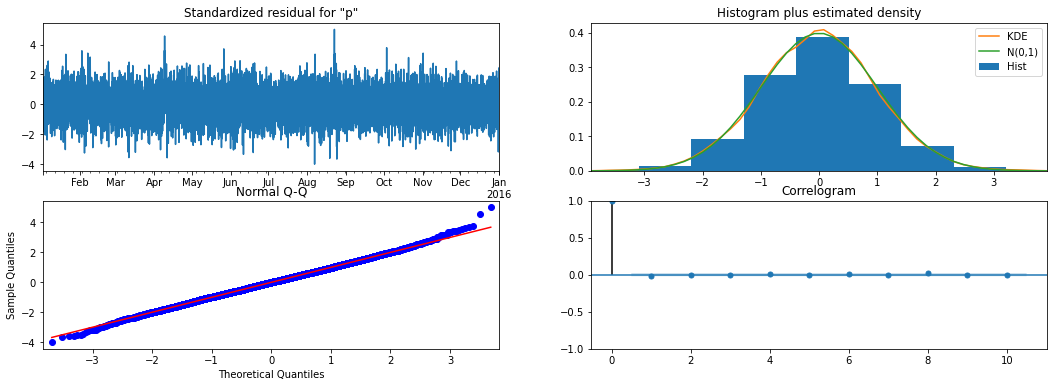

In [ ]:
resultados.plot_diagnostics(figsize=(18, 6));
plt.show()

## Intervalo de confiança

In [ ]:
pred = resultados.get_prediction(start=pd.to_datetime('2015-01-03'), end=pd.to_datetime('2015-12-31'), dynamic=False)

pred_interval_conf = pred.conf_int()

pred_interval_conf

,lower pressure,upper pressure
2015-01-03 00:00:00,70.546352,128.663545
2015-01-03 01:00:00,65.266585,123.376663
2015-01-03 02:00:00,84.777137,142.877650
2015-01-03 03:00:00,83.134988,141.223301
2015-01-03 04:00:00,48.465080,106.538394
...,...,...
2015-12-30 20:00:00,80.119055,121.660211
2015-12-30 21:00:00,79.026988,120.568144
2015-12-30 22:00:00,81.348327,122.889482
2015-12-30 23:00:00,82.744805,124.285961


## Previsão para dados existentes

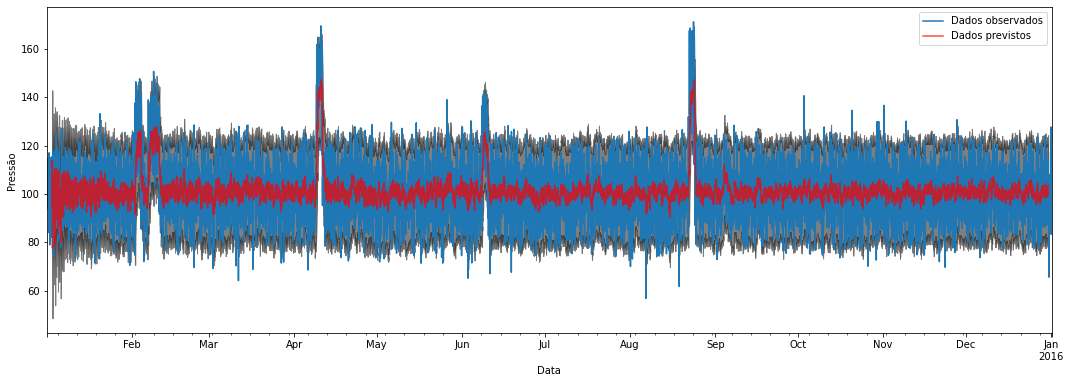

In [ ]:
ax = y['2015':].plot(label='Dados observados')

# Cálculo da média móvel
pred.predicted_mean.plot(ax=ax, label='Dados previstos', color='r', alpha=0.7, figsize=(18, 6))

ax.fill_between(pred_interval_conf.index, pred_interval_conf.iloc[:, 0], pred_interval_conf.iloc[:, 1], color='k', alpha=0.5)
ax.set_xlabel('Data')
ax.set_ylabel('Pressão')
plt.legend()

## Previsão para dados do futuro (inexistentes no dataset)

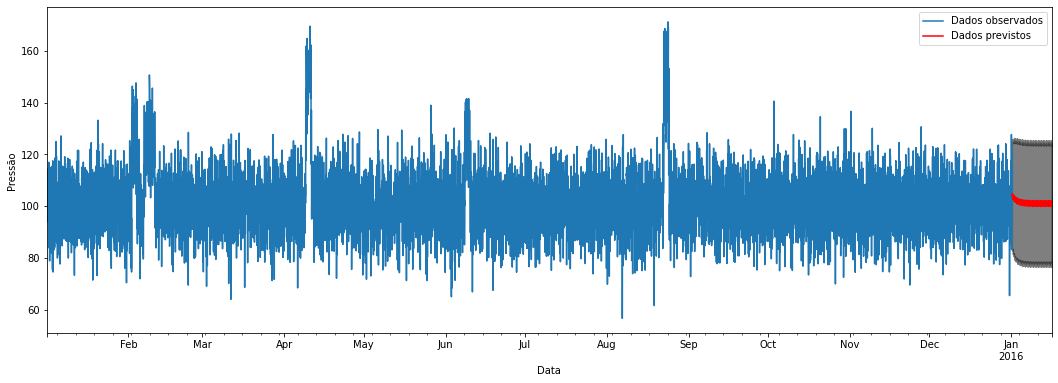

In [ ]:
pred_uc = resultados.get_forecast(steps=360) # previsão de 360 h à frente

pred_interval_conf = pred_uc.conf_int()

ax = y.plot(label='Dados observados', figsize=(18, 6))

pred_uc.predicted_mean.plot(ax=ax, label='Dados previstos', color='r')

ax.fill_between(pred_interval_conf.index, pred_interval_conf.iloc[:, 0], pred_interval_conf.iloc[:, 1], color='k', alpha=0.5)
ax.set_xlabel('Data')
ax.set_ylabel('Pressão')
plt.legend()

**Falta a última aula antes do desafio**
"Prevendo e comparando"